In [1]:
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

In [2]:
import xgboost

print(xgboost.__version__)

3.4.1


In [3]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = pd.Series(
    iris.target,
    name="target"
)

In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nClasses:")
print(iris.target_names)

X shape: (150, 4)
y shape: (150,)

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Classes:
['setosa' 'versicolor' 'virginica']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [7]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

In [8]:
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklear

In [10]:
y_pred = xgb_model.predict(X_test)
print(y_pred)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 2 2 2 1 0 2 0]


In [11]:
y_proba = xgb_model.predict_proba(X_test)

print(y_proba[:5])

[[0.99106497 0.00665401 0.00228102]
 [0.01162235 0.11016721 0.8782104 ]
 [0.01545399 0.9657826  0.01876341]
 [0.01545399 0.9657826  0.01876341]
 [0.99106497 0.00665401 0.00228102]]


In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)


Accuracy: 0.9333333333333333


In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [14]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [15]:
train_pred = xgb_model.predict(X_train)
test_pred = xgb_model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Training Accuracy: 1.0
Test Accuracy: 0.9333333333333333


In [16]:
tree_counts = [10, 25, 50, 100, 200]

for n in tree_counts:

    model = XGBClassifier(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(
        f"n_estimators={n}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

n_estimators=10: Train=0.983, Test=0.967
n_estimators=25: Train=0.983, Test=0.967
n_estimators=50: Train=0.992, Test=0.933
n_estimators=100: Train=1.000, Test=0.933
n_estimators=200: Train=1.000, Test=0.933


In [17]:
learning_rates = [0.01, 0.05, 0.1, 0.2, 0.3]

for lr in learning_rates:
    model = XGBClassifier(
        n_estimators=100,
        learning_rate=lr,
        max_depth=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(
        f"learning_rate={lr}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

learning_rate=0.01: Train=0.983, Test=0.967
learning_rate=0.05: Train=0.992, Test=0.933
learning_rate=0.1: Train=1.000, Test=0.933
learning_rate=0.2: Train=1.000, Test=0.933
learning_rate=0.3: Train=1.000, Test=0.933


In [18]:
depths = [1, 2, 3, 4, 5, 6]

for depth in depths:
    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(
        f"max_depth={depth}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

max_depth=1: Train=0.992, Test=0.967
max_depth=2: Train=1.000, Test=0.900
max_depth=3: Train=1.000, Test=0.933
max_depth=4: Train=1.000, Test=0.933
max_depth=5: Train=1.000, Test=0.933
max_depth=6: Train=1.000, Test=0.933


In [19]:
subsample_values = [0.5, 0.7, 0.8, 1.0]

for subsample in subsample_values:
    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=subsample,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(
        f"subsample={subsample}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

subsample=0.5: Train=0.992, Test=0.900
subsample=0.7: Train=1.000, Test=0.933
subsample=0.8: Train=1.000, Test=0.933
subsample=1.0: Train=1.000, Test=0.933


In [20]:
colsample_values = [0.5, 0.7, 0.8, 1.0]

for colsample in colsample_values:
    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=colsample,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(
        f"colsample_bytree={colsample}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

colsample_bytree=0.5: Train=1.000, Test=0.933
colsample_bytree=0.7: Train=1.000, Test=0.933
colsample_bytree=0.8: Train=1.000, Test=0.933
colsample_bytree=1.0: Train=1.000, Test=0.933


In [21]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

             Feature  Importance
3   petal width (cm)    0.499138
2  petal length (cm)    0.459065
1   sepal width (cm)    0.022007
0  sepal length (cm)    0.019789


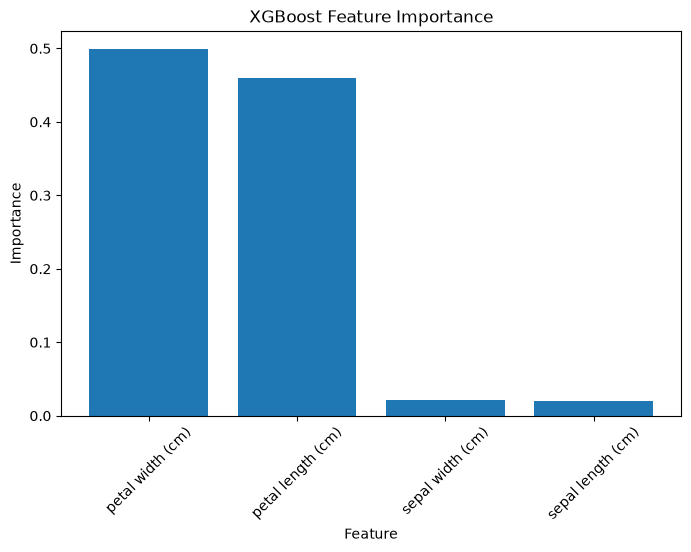

In [23]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("XGBoost Feature Importance")
plt.xticks(rotation=45)
plt.show()

In [24]:
new_flower = pd.DataFrame({
    "sepal length (cm)": [5.1],
    "sepal width (cm)": [3.5],
    "petal length (cm)": [1.4],
    "petal width (cm)": [0.2]
})
prediction = xgb_model.predict(new_flower)
print("Predicted class number:", prediction[0])
print("Predicted flower:", iris.target_names[prediction[0]])
probabilities = xgb_model.predict_proba(new_flower)
print(probabilities)

Predicted class number: 0
Predicted flower: setosa
[[0.99106497 0.00665401 0.00228102]]


In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(
        f"{name}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

Decision Tree: Train=0.983, Test=0.967
Random Forest: Train=1.000, Test=0.900
XGBoost: Train=1.000, Test=0.933
